In [1]:
import numpy as np

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")
print(np.__version__)
print("Everything is working!")

2.4.6
Everything is working!


In [3]:

data = pd.read_csv("insurance.csv")

In [4]:
data


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


EDA


In [5]:
data.shape


(1338, 7)

In [6]:
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [8]:
data.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [9]:
data.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [10]:
data.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

In [11]:
numeric_columms  = [ 'age', 'bmi', 'children', 'charges']

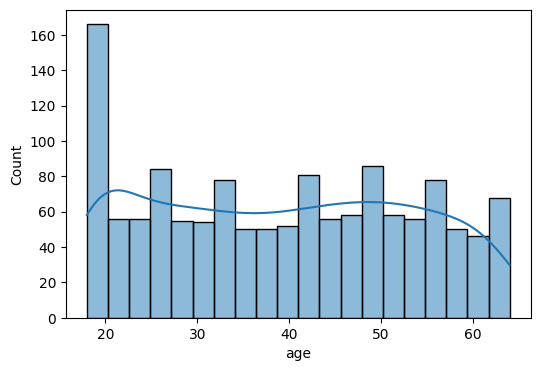

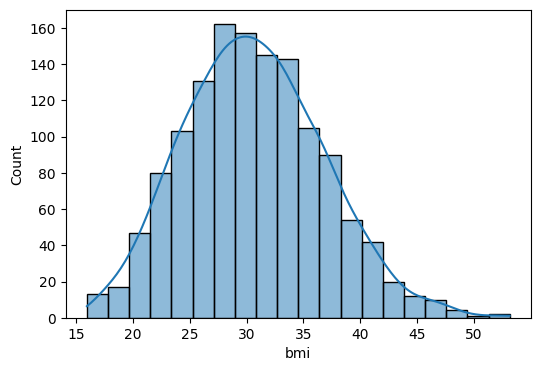

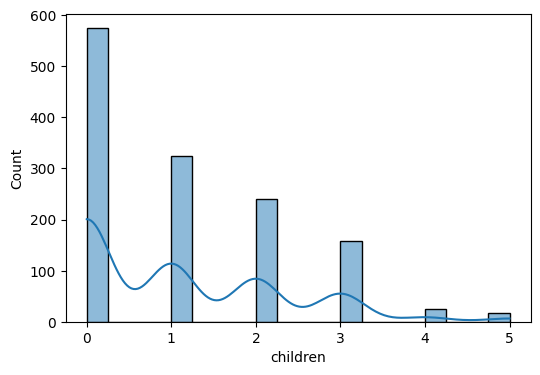

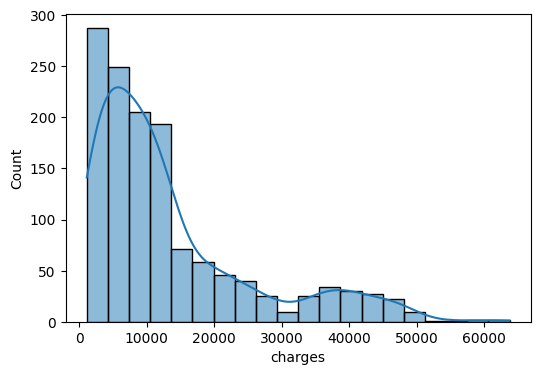

In [12]:
for col in numeric_columms:
    plt.figure(figsize=(6,4))
    sns.histplot(data[col],kde = True ,bins =20)
    

<Axes: xlabel='children', ylabel='count'>

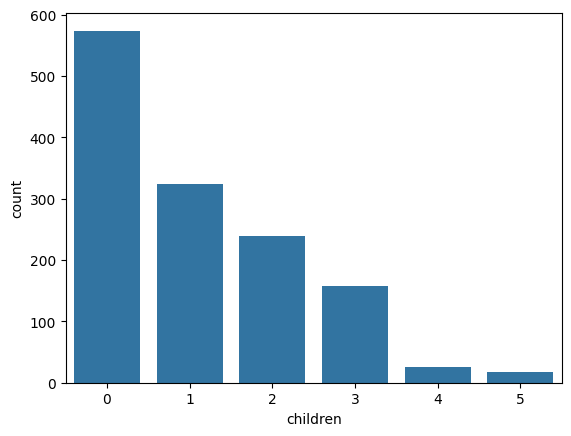

In [13]:
sns.countplot( x= data['children'])

<Axes: xlabel='count', ylabel='sex'>

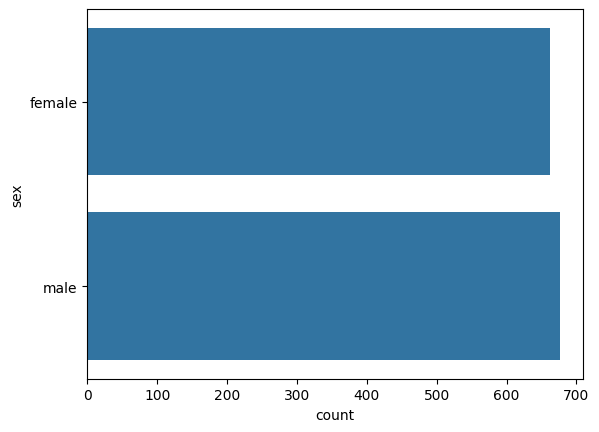

In [14]:
sns.countplot(data["sex"])

<Axes: xlabel='count', ylabel='smoker'>

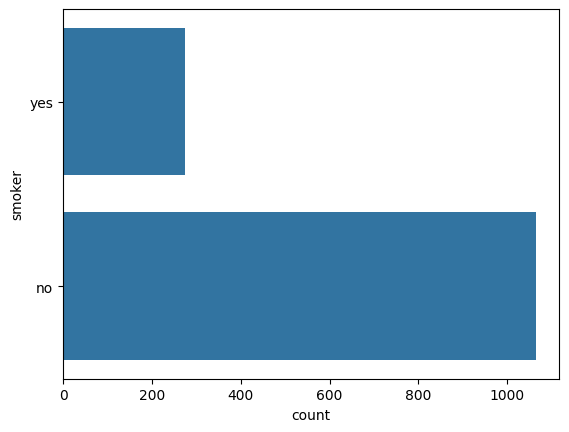

In [15]:
sns.countplot(data['smoker'])

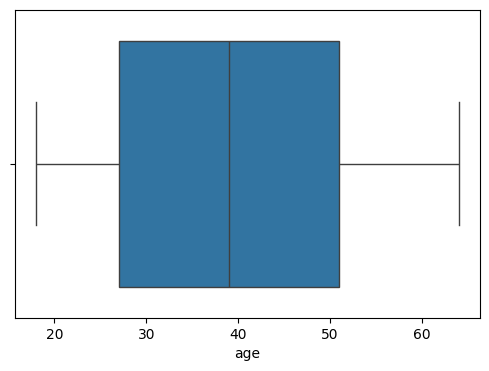

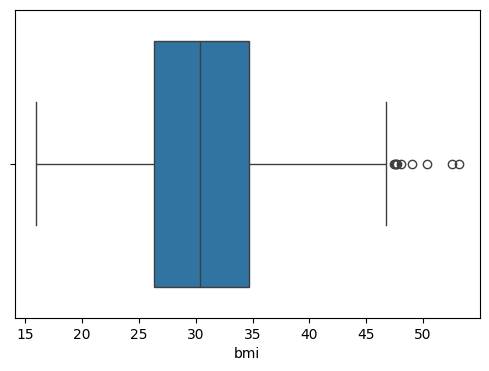

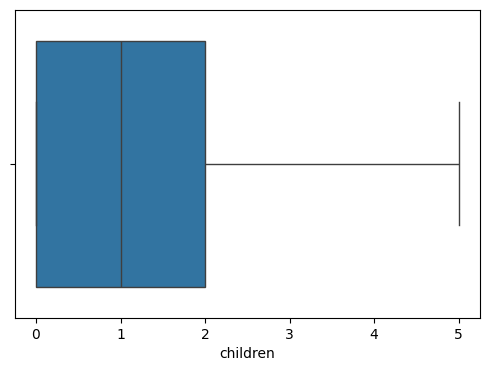

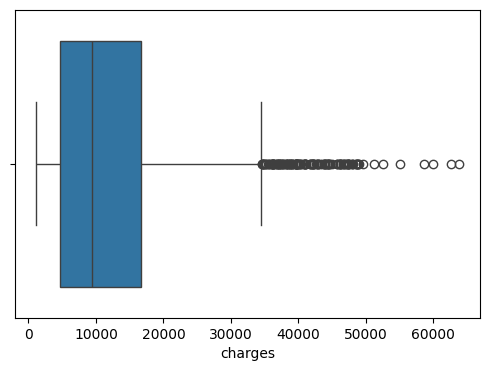

In [16]:
for col in numeric_columms:
    plt.figure(figsize=(6,4))
    sns.boxplot(x = data[col])

<Axes: >

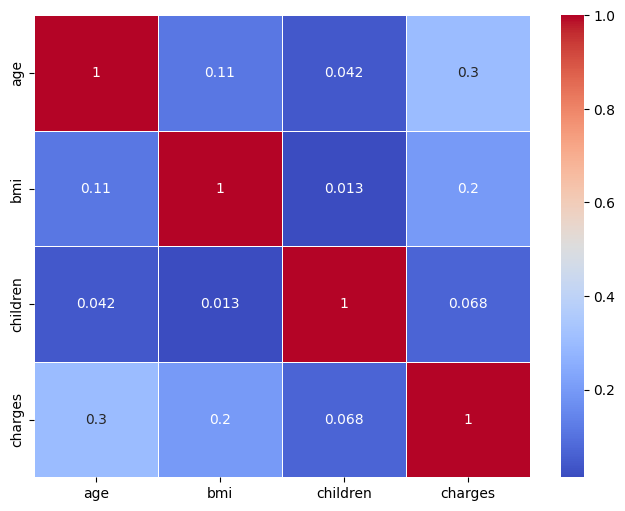

In [17]:
plt.figure(figsize=(8,6))
sns.heatmap(data.corr(numeric_only=True), annot = True, cmap = 'coolwarm', linewidths = 0.5)

#Data cleannig And Preprocessing

In [18]:
data_cleaned = data.copy()

In [19]:
data_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [20]:
data_cleaned.shape

(1338, 7)

In [21]:
data_cleaned.drop_duplicates(inplace = True)

In [22]:
data_cleaned.shape

(1337, 7)

In [23]:
data_cleaned.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [24]:
data_cleaned.dtypes

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

now lets convert everthing inyto numerical which is essential for machine learning

In [25]:
data_cleaned['sex'].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

converting the sex and smoker  , region encoding ie means converting into zeroes

In [26]:
# label encoding

In [27]:
data_cleaned['sex'] = data_cleaned['sex'].map({"male":0 , "female":1})

In [28]:
data_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.46200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520


In [29]:
data_cleaned['smoker'].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [30]:
data_cleaned['smoker']= data_cleaned['smoker'].map({"yes":1 , "no":0})

In [31]:
data_cleaned

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,northwest,10600.54830
1334,18,1,31.920,0,0,northeast,2205.98080
1335,18,1,36.850,0,0,southeast,1629.83350
1336,21,1,25.800,0,0,southwest,2007.94500


In [32]:
data_cleaned.rename(columns ={
    'sex':'is_female',
    'smoker':'is_smoker'

},inplace = True)

In [33]:
data_cleaned.head()

,age,is_female,bmi,children,is_smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [34]:
data_cleaned['region'].value_counts()   

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

In [35]:
df =data_cleaned

In [36]:
# 1 hot encoding

In [37]:
df = pd.get_dummies(df,columns = ['region'],drop_first = True)

In [38]:
df.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,False,False,True
1,18,0,33.770,1,0,1725.55230,False,True,False
2,28,0,33.000,3,0,4449.46200,False,True,False
3,33,0,22.705,0,0,21984.47061,True,False,False
4,32,0,28.880,0,0,3866.85520,True,False,False


In [39]:
df =df.astype(int)

In [40]:
df

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27,0,1,16884,0,0,1
1,18,0,33,1,0,1725,0,1,0
2,28,0,33,3,0,4449,0,1,0
3,33,0,22,0,0,21984,1,0,0
4,32,0,28,0,0,3866,1,0,0
...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,1,0,0
1334,18,1,31,0,0,2205,0,0,0
1335,18,1,36,0,0,1629,0,1,0
1336,21,1,25,0,0,2007,0,0,1


In [41]:
#FEATURE ENGINEERING ANDD EXTRACTION 

#FEATURE ENGINEERING ANDD EXTRACTION 

<Axes: xlabel='bmi', ylabel='Count'>

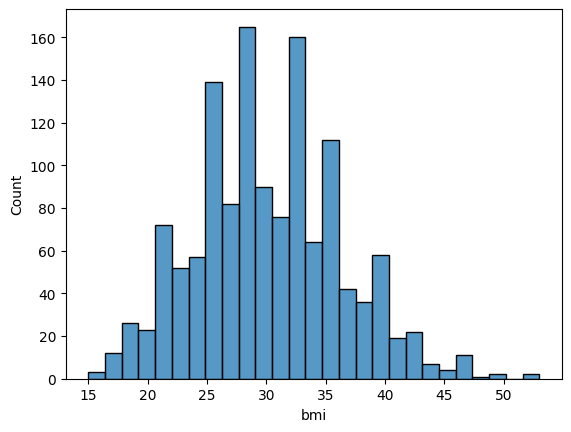

In [42]:
sns.histplot(df["bmi"])

In [43]:
from logging import info


df["bmi_category"] = pd.cut(
    df["bmi"] ,
    bins=[0,18.5 , 24.9 , 29.9 , float('inf')],
    labels = ['underweight','normal','overweight','obese']

)

In [44]:
df

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category
0,19,1,27,0,1,16884,0,0,1,overweight
1,18,0,33,1,0,1725,0,1,0,obese
2,28,0,33,3,0,4449,0,1,0,obese
3,33,0,22,0,0,21984,1,0,0,normal
4,32,0,28,0,0,3866,1,0,0,overweight
...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,1,0,0,obese
1334,18,1,31,0,0,2205,0,0,0,obese
1335,18,1,36,0,0,1629,0,1,0,obese
1336,21,1,25,0,0,2007,0,0,1,overweight


In [45]:
df = pd.get_dummies(df,columns = ['bmi_category'],drop_first = True)

In [46]:
df=df.astype(int)

In [47]:
df.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_normal,bmi_category_overweight,bmi_category_obese
0,19,1,27,0,1,16884,0,0,1,0,1,0
1,18,0,33,1,0,1725,0,1,0,0,0,1
2,28,0,33,3,0,4449,0,1,0,0,0,1
3,33,0,22,0,0,21984,1,0,0,1,0,0
4,32,0,28,0,0,3866,1,0,0,0,1,0


In [48]:
df.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi_category_normal', 'bmi_category_overweight', 'bmi_category_obese'],
      dtype='str')

In [49]:
from sklearn.preprocessing import StandardScaler
cols = ['age', 'bmi', 'children',]
scaler = StandardScaler()   
df[cols] = scaler.fit_transform(df[cols])   

In [50]:
df.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_normal,bmi_category_overweight,bmi_category_obese
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,1,0,1,0
1,-1.511647,0,0.462463,-0.079442,0,1725,0,1,0,0,0,1
2,-0.799350,0,0.462463,1.580143,0,4449,0,1,0,0,0,1
3,-0.443201,0,-1.334960,-0.909234,0,21984,1,0,0,1,0,0
4,-0.514431,0,-0.354547,-0.909234,0,3866,1,0,0,0,1,0


In [51]:
from scipy.stats import pearsonr
import pandas as pd

# Pearson Correlation Coefficient

selected_features = [
    'age',
    'bmi',
    'children',
    'is_female',
    'is_smoker',
    'region_northwest',
    'region_southeast',
    'region_southwest',
    'bmi_category_normal',
    'bmi_category_overweight',
    'bmi_category_obese'
]

correlations = {
    feature: pearsonr(df[feature], df['charges'])[0]
    for feature in selected_features
}

correlation_df = pd.DataFrame(
    list(correlations.items()),
    columns=['Feature', 'pearson_correlation']
)

correlation_df = correlation_df.sort_values(
    by='pearson_correlation',
    ascending=False
)

print(correlation_df)



                    Feature  pearson_correlation
4                 is_smoker             0.787234
0                       age             0.298309
10       bmi_category_obese             0.200348
1                       bmi             0.196236
6          region_southeast             0.073577
2                  children             0.067390
5          region_northwest            -0.038695
7          region_southwest            -0.043637
3                 is_female            -0.058046
8       bmi_category_normal            -0.104042
9   bmi_category_overweight            -0.120601


In [52]:
cat_features = ['is_female', 'is_smoker', 'region_northwest', 'region_southeast', 'region_southwest', 'bmi_category_normal', 'bmi_category_overweight', 'bmi_category_obese']


In [53]:
from scipy.stats import chi2_contingency
import pandas as pd

alpha = 0.05

# Convert continuous target into 4 categories
df['charges_bin'] = pd.qcut(df['charges'], q=4, labels=False)

chi2_results = {}

for col in cat_features:
    # Create contingency table
    contingency_table = pd.crosstab(df[col], df['charges_bin'])

    # Perform Chi-Square Test
    chi2_stat, p_value, dof, expected = chi2_contingency(contingency_table)

    # Decision
    decision = (
        'Reject Null (Keep the Feature)'
        if p_value < alpha
        else 'Fail to Reject Null (Drop the Feature)'
    )

    # Store results
    chi2_results[col] = {
        'Chi2 Statistic': chi2_stat,
        'p-value': p_value,
        'Decision': decision
    }

# Convert dictionary to DataFrame
chi2_df = pd.DataFrame(chi2_results).T

# Sort by p-value
chi2_df = chi2_df.sort_values(by='p-value')

# Display results
print(chi2_df)

                        Chi2 Statistic   p-value  \
is_smoker                   848.219178       0.0   
region_southeast             15.998167  0.001135   
is_female                    10.258784   0.01649   
bmi_category_obese            8.515711  0.036473   
region_southwest              5.091893  0.165191   
bmi_category_overweight        4.25149  0.235557   
bmi_category_normal           3.708088   0.29476   
region_northwest               1.13424  0.768815   

                                                       Decision  
is_smoker                        Reject Null (Keep the Feature)  
region_southeast                 Reject Null (Keep the Feature)  
is_female                        Reject Null (Keep the Feature)  
bmi_category_obese               Reject Null (Keep the Feature)  
region_southwest         Fail to Reject Null (Drop the Feature)  
bmi_category_overweight  Fail to Reject Null (Drop the Feature)  
bmi_category_normal      Fail to Reject Null (Drop the Feature)  
reg

In [54]:
final_df = df[['age', 'bmi', 'children', 'is_female', 'is_smoker',
               'region_southeast', 'bmi_category_obese', 'charges']]

In [55]:
final_df

,age,bmi,children,is_female,is_smoker,region_southeast,bmi_category_obese,charges
0,-1.440418,-0.517949,-0.909234,1,1,0,0,16884
1,-1.511647,0.462463,-0.079442,0,0,1,1,1725
2,-0.799350,0.462463,1.580143,0,0,1,1,4449
3,-0.443201,-1.334960,-0.909234,0,0,0,0,21984
4,-0.514431,-0.354547,-0.909234,0,0,0,0,3866
...,...,...,...,...,...,...,...,...
1333,0.767704,-0.027743,1.580143,0,0,0,1,10600
1334,-1.511647,0.135659,-0.909234,1,0,0,1,2205
1335,-1.511647,0.952670,-0.909234,1,0,1,1,1629
1336,-1.297958,-0.844753,-0.909234,1,0,0,0,2007


In [56]:
from sklearn.model_selection import train_test_split

In [57]:
x = final_df.drop('charges', axis=1 )
y = final_df['charges']

In [58]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [59]:
from sklearn.linear_model import LinearRegression

In [60]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 3489.11, 565.67, 645.81,...,23080.28, -264.14, 3285.92]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['age','bmi','children',...,'is_smoker','region_southeast', 'bmi_category_obese']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,6769
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,7


In [61]:
y_pred = model.predict(X_test)

In [62]:
y_pred

array([ 7856.41808069,  5379.07145062, 14613.47489419, 32465.93193508,
        8955.35729283, 13336.43605749, 30199.07309038,  1403.40503994,
       11196.90873514, 10018.65838301, 10818.71629044, 32144.43533014,
       31550.26059902, 16230.55597963, 10285.99989714,  8488.6608457 ,
        5487.64476113, 32465.09672212,  3304.46601962,  3877.00422671,
        4760.01023433, 28796.29743032, 13870.98195763, 29541.88243902,
       31520.15678042,  6344.44675222, 35026.69683204, 37880.73853364,
       12490.06211178, 14238.95332785,  7573.09915473, 13049.08020135,
         516.21534048, 11339.74207305, 37584.28749479, 13356.84393437,
        3706.96614326,  4537.12786929, 31481.80485676,  8009.55465514,
        6075.79442888, 30404.81913857, 35276.56346051, 13099.59189682,
        7977.69705664,  2987.00634487,  5174.11237148,  7620.54073087,
        3522.89053725, 10388.99625751,  7820.00530896, 10505.68054495,
       30331.09138384,  4687.62077185, 11676.0149257 , 11446.77536361,
      

In [63]:
from sklearn.metrics import r2_score
r2 = r2_score(y_test, y_pred)   

In [64]:
r2

0.8040712413347119

In [68]:
n = X_test.shape[0] 
p = X_test.shape[1]  # number of features
adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
adjusted_r2

0.7987962362937233